# Skill 5 – Case Study 3: Banking Transaction Anomalies

**Objective:** Flag unusual banking transactions for review. An anomaly is not automatically fraud; every alert requires appropriate human review.

This notebook creates a reproducible **synthetic dataset of 20,000 transactions**. It uses artificial customer and merchant identifiers, with no real personal or financial information. The data is for learning only and is not representative of any bank.

**Target label:** `known_anomaly` (1 = transaction is synthetically labelled unusual; 0 = transaction is synthetically labelled routine). This label is used only for retrospective evaluation. In a real deployment, anomaly detection can be unsupervised or reviewed against confirmed investigation outcomes.

## tl;dr

This notebook generates transaction records, performs EDA by amount/channel/time, checks repeated merchants, missingness and class imbalance, engineers customer-history features, and compares a simple rule-based baseline with a supervised Logistic Regression model using chronological validation and testing.

All results are calculated from synthetic data. They are not estimates of real fraud prevalence, bank loss, or model performance.

## Context & Methods

### Business question
Which transactions differ from a customer's recent spending behaviour or normal transaction pattern enough to warrant a review?

### Unit of analysis and prediction point
Each row represents one transaction. A transaction is scored at its event time. Customer-history features use only transactions strictly earlier than the current transaction.

### Key assumptions
- Synthetic data is generated with a fixed random seed.
- `known_anomaly` is an artificial teaching label for unusual patterns, not a legal or operational fraud determination.
- Transaction amounts are expressed in INR for illustration.
- Customer and merchant identifiers are random pseudonymous IDs; no names, account numbers, phone numbers or addresses are generated.
- The transaction frequency feature counts earlier transactions in the preceding 60 minutes.
- Time-based splits are used: earlier data for training, then validation, then later test data.
- A human analyst reviews alerts before any customer or transaction action.
- In real systems, use least-privilege access, retention limits, encryption, audit logs and approved access to customer data.

## Data

### 1. Imports and reproducibility

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, average_precision_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
N_TRANSACTIONS = 20_000
N_CUSTOMERS = 1_200
N_MERCHANTS = 350

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 130)

### 2. Generate synthetic transaction records

Transactions are generated across several weeks. Some unusual examples have unusually large amounts, bursts of activity, or unusual transaction hours. The label is an artificial teaching label derived from these patterns plus random noise.

In [2]:
rng = np.random.default_rng(RANDOM_STATE)

customer_ids = np.array([f"C{value:05d}" for value in range(1, N_CUSTOMERS + 1)])
merchant_ids = np.array([f"M{value:04d}" for value in range(1, N_MERCHANTS + 1)])

# Generate transaction timestamps across 60 days, then sort chronologically.
start_time = pd.Timestamp("2026-01-01 00:00:00")
event_seconds = rng.integers(0, 60 * 24 * 60 * 60, size=N_TRANSACTIONS)
transaction_time = start_time + pd.to_timedelta(event_seconds, unit="s")

customer_id = rng.choice(customer_ids, size=N_TRANSACTIONS)
merchant_id = rng.choice(merchant_ids, size=N_TRANSACTIONS)

channel = rng.choice(
    ["Card Present", "Online", "Mobile Wallet", "ATM"],
    size=N_TRANSACTIONS,
    p=[0.38, 0.34, 0.20, 0.08]
)

# Customer-specific typical spend scale; this is simulated latent variation.
customer_spend_scale = {
    cid: rng.lognormal(mean=np.log(1400), sigma=0.55)
    for cid in customer_ids
}
base_amount = np.array([customer_spend_scale[cid] for cid in customer_id])

channel_multiplier = pd.Series(channel).map({
    "Card Present": 0.85,
    "Online": 1.05,
    "Mobile Wallet": 0.55,
    "ATM": 1.20
}).to_numpy()

amount = rng.lognormal(
    mean=np.log(np.maximum(base_amount * channel_multiplier, 50)),
    sigma=0.75
)

# Add an artificial small group of unusually large-value transactions.
synthetic_unusual = rng.binomial(1, 0.035, size=N_TRANSACTIONS)
amount = np.where(
    synthetic_unusual == 1,
    amount * rng.uniform(4, 12, size=N_TRANSACTIONS),
    amount
)
amount = np.round(np.clip(amount, 20, 250000), 2)

df = pd.DataFrame({
    "transaction_id": [f"T{value:07d}" for value in range(1, N_TRANSACTIONS + 1)],
    "customer_id": customer_id,
    "merchant_id": merchant_id,
    "transaction_time": transaction_time,
    "channel": channel,
    "amount_inr": amount,
    "_synthetic_unusual_seed": synthetic_unusual
})

df = df.sort_values("transaction_time").reset_index(drop=True)

# Label unusual patterns using amount relative to the customer's typical scale,
# transaction timing, and the artificial unusual seed.
hour = df["transaction_time"].dt.hour
amount_ratio_seed = df["amount_inr"].to_numpy() / np.array(
    [customer_spend_scale[cid] for cid in df["customer_id"]]
)
unusual_score = (
    1.6 * (amount_ratio_seed > 4)
    + 1.1 * ((hour < 5) | (hour >= 23)).to_numpy()
    + 1.8 * df["_synthetic_unusual_seed"].to_numpy()
    + rng.normal(0, 0.35, size=len(df))
)

df["known_anomaly"] = (unusual_score >= 1.65).astype(int)

# Remove helper column so it cannot be used as a model predictor.
df = df.drop(columns="_synthetic_unusual_seed")

# Add missing values to a small number of amounts to demonstrate missingness handling.
missing_amount_idx = rng.choice(df.index, size=100, replace=False)
df.loc[missing_amount_idx, "amount_inr"] = np.nan

# Export a portable CSV.
df.to_csv("banking_transactions_synthetic.csv", index=False)

print("Synthetic transaction dataset created.")
print("Shape:", df.shape)
display(df.head())

Synthetic transaction dataset created.
Shape: (20000, 7)


,transaction_id,customer_id,merchant_id,transaction_time,channel,amount_inr,known_anomaly
0,T0005082,C00100,M0212,2026-01-01 00:00:04,Card Present,639.00,0
1,T0010962,C00704,M0051,2026-01-01 00:27:09,Online,5376.55,0
2,T0018689,C00568,M0027,2026-01-01 00:33:28,Mobile Wallet,2029.21,0
3,T0008282,C00773,M0292,2026-01-01 00:35:51,Card Present,2779.48,0
4,T0012238,C00356,M0310,2026-01-01 00:36:01,Card Present,366.86,0


### 3. Validate data quality and privacy-minimizing structure
Check data types, duplicate transaction IDs, missing values, valid labels and the columns included in the dataset.

In [3]:
print("Dataset shape:", df.shape)
print("\nData types and non-null counts:")
df.info()

print("\nDuplicate transaction IDs:", df["transaction_id"].duplicated().sum())
print("Duplicate full rows:", df.duplicated().sum())
print("\nLabel distribution:")
display(df["known_anomaly"].value_counts().rename(index={0: "Routine", 1: "Synthetic anomaly"}).to_frame("transactions"))

print("\nColumns:")
print(df.columns.tolist())

assert df["transaction_id"].is_unique
assert set(df["known_anomaly"].dropna().unique()).issubset({0, 1})
assert (df["amount_inr"].dropna() > 0).all()

Dataset shape: (20000, 7)

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   transaction_id    20000 non-null  object        
 1   customer_id       20000 non-null  object        
 2   merchant_id       20000 non-null  object        
 3   transaction_time  20000 non-null  datetime64[ns]
 4   channel           20000 non-null  object        
 5   amount_inr        19900 non-null  float64       
 6   known_anomaly     20000 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int64(1), object(4)
memory usage: 1.1+ MB

Duplicate transaction IDs: 0
Duplicate full rows: 0

Label distribution:


,transactions
known_anomaly,
Routine,18731
Synthetic anomaly,1269



Columns:
['transaction_id', 'customer_id', 'merchant_id', 'transaction_time', 'channel', 'amount_inr', 'known_anomaly']


## Results

## Task A – Exploratory Data Analysis

### 4. Missing values and class imbalance

,missing_count,missing_percent
amount_inr,100,0.5
customer_id,0,0.0
transaction_id,0,0.0
merchant_id,0,0.0
transaction_time,0,0.0
channel,0,0.0
known_anomaly,0,0.0


Class percentages:


,percentage
known_anomaly,
Routine,93.655
Synthetic anomaly,6.345


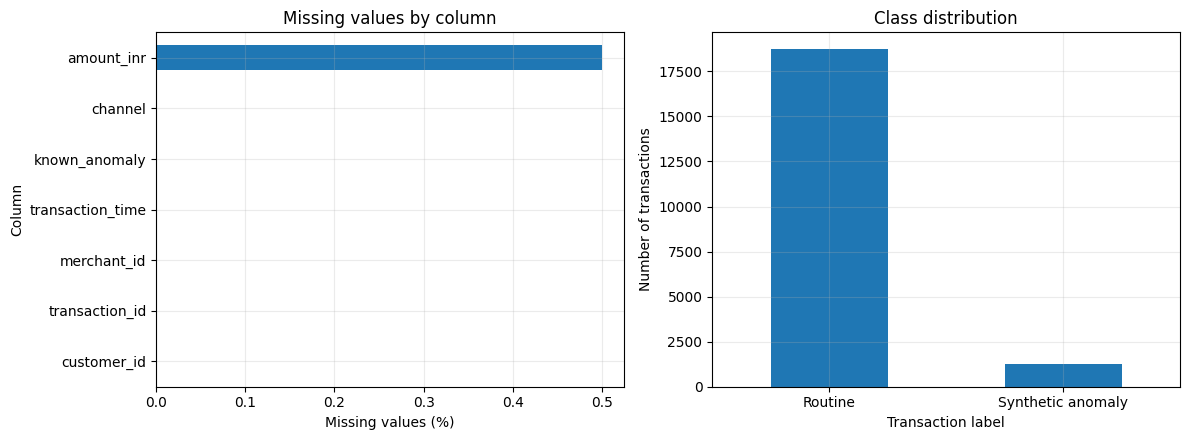

In [4]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)

display(missing_summary)

anomaly_counts = df["known_anomaly"].value_counts().sort_index()
anomaly_rates = df["known_anomaly"].value_counts(normalize=True).sort_index() * 100

print("Class percentages:")
display(anomaly_rates.rename(index={0: "Routine", 1: "Synthetic anomaly"}).to_frame("percentage"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
missing_summary["missing_percent"].sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Missing values by column")
axes[0].set_xlabel("Missing values (%)")
axes[0].set_ylabel("Column")

anomaly_counts.rename(index={0: "Routine", 1: "Synthetic anomaly"}).plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Class distribution")
axes[1].set_xlabel("Transaction label")
axes[1].set_ylabel("Number of transactions")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

### 5. Transaction amount by channel

Amounts are right-skewed, so the chart uses a logarithmic vertical axis. Summary statistics are included for exact comparison.

,transactions,mean_amount,median_amount,p95_amount
channel,,,,
ATM,1621,3042.63,1663.72,9521.48
Online,6816,2732.70,1519.53,8703.95
Card Present,7537,2160.60,1190.94,6395.26
Mobile Wallet,4026,1561.68,803.29,4751.50


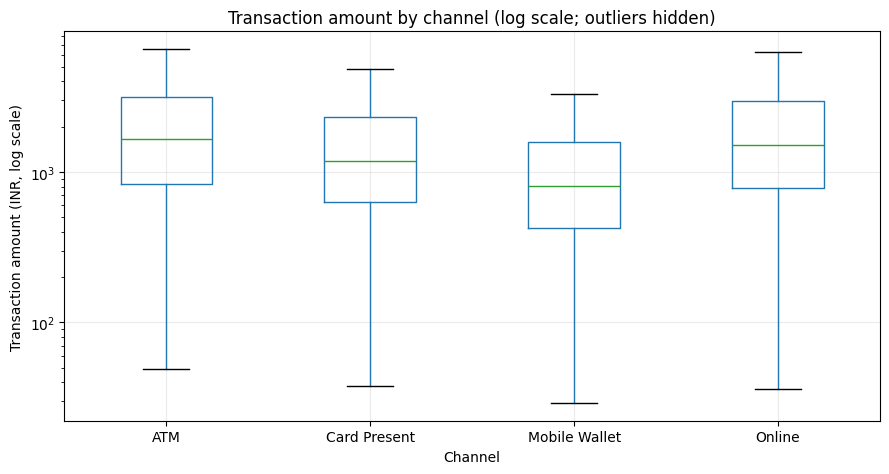

In [5]:
amount_by_channel = (
    df.groupby("channel")
      .agg(
          transactions=("transaction_id", "count"),
          mean_amount=("amount_inr", "mean"),
          median_amount=("amount_inr", "median"),
          p95_amount=("amount_inr", lambda x: x.quantile(0.95))
      )
      .sort_values("median_amount", ascending=False)
)
display(amount_by_channel.round(2))

fig, ax = plt.subplots(figsize=(9, 5))
df.boxplot(column="amount_inr", by="channel", ax=ax, showfliers=False)
ax.set_yscale("log")
ax.set_title("Transaction amount by channel (log scale; outliers hidden)")
ax.set_xlabel("Channel")
ax.set_ylabel("Transaction amount (INR, log scale)")
plt.suptitle("")
plt.tight_layout()
plt.show()

### 6. Transaction amount by time

Compare median transaction amount and transaction volume by hour. A time pattern alone is not evidence of fraud; customer routines and time zones matter.

,transaction_count,median_amount,anomaly_rate,anomaly_rate_pct
transaction_hour,,,,
0,819,1259.92,0.10,10.26
1,842,1195.03,0.10,10.45
2,823,1218.22,0.12,12.39
3,816,1121.14,0.12,12.50
4,891,1264.98,0.12,12.12
5,809,1207.48,0.05,4.82
6,852,1265.90,0.04,4.11
7,853,1206.06,0.04,3.99
8,824,1250.21,0.04,4.00


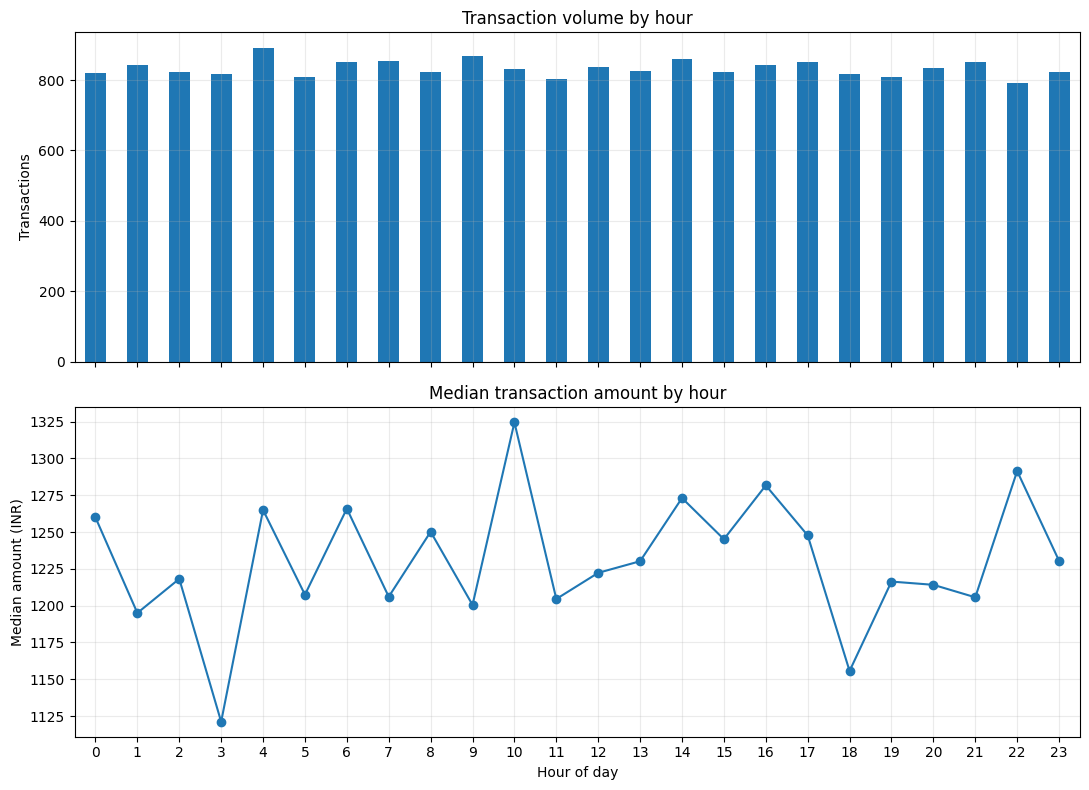

In [6]:
df["transaction_hour"] = df["transaction_time"].dt.hour

hourly_summary = (
    df.groupby("transaction_hour")
      .agg(
          transaction_count=("transaction_id", "count"),
          median_amount=("amount_inr", "median"),
          anomaly_rate=("known_anomaly", "mean")
      )
)
hourly_summary["anomaly_rate_pct"] = hourly_summary["anomaly_rate"] * 100
display(hourly_summary.round(2))

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
hourly_summary["transaction_count"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Transaction volume by hour")
axes[0].set_ylabel("Transactions")

hourly_summary["median_amount"].plot(kind="line", marker="o", ax=axes[1])
axes[1].set_title("Median transaction amount by hour")
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("Median amount (INR)")
axes[1].set_xticks(range(0, 24))

plt.tight_layout()
plt.show()

### 7. Repeated merchants

Repeated merchants are common in normal banking activity. We inspect merchant volume and the proportion of synthetic anomalies, but repeated use alone must not trigger a fraud decision.

Most frequently used merchants:


,transaction_count,median_amount,synthetic_anomaly_rate
merchant_id,,,
M0196,79,1527.490,0.038
M0009,77,1421.540,0.039
M0239,77,1269.070,0.039
M0081,77,1632.400,0.026
M0189,77,1101.885,0.078
M0085,76,1190.945,0.053
M0058,74,1254.910,0.068
M0061,73,966.200,0.014
M0224,72,1253.620,0.069


Merchants with more than one transaction: 350 of 350


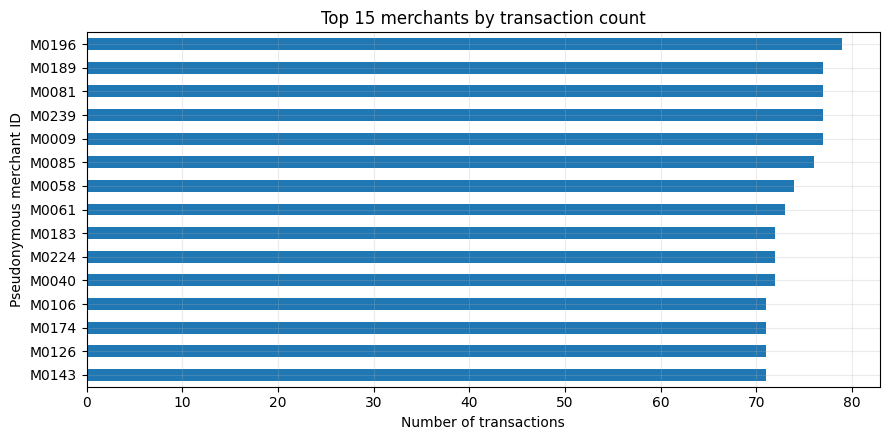

In [7]:
merchant_summary = (
    df.groupby("merchant_id")
      .agg(
          transaction_count=("transaction_id", "count"),
          median_amount=("amount_inr", "median"),
          synthetic_anomaly_rate=("known_anomaly", "mean")
      )
      .sort_values("transaction_count", ascending=False)
)

print("Most frequently used merchants:")
display(merchant_summary.head(15).round(3))

repeat_merchant_count = int((merchant_summary["transaction_count"] > 1).sum())
print(f"Merchants with more than one transaction: {repeat_merchant_count} of {len(merchant_summary)}")

fig, ax = plt.subplots(figsize=(9, 4.5))
merchant_summary.head(15)["transaction_count"].sort_values().plot(kind="barh", ax=ax)
ax.set_title("Top 15 merchants by transaction count")
ax.set_xlabel("Number of transactions")
ax.set_ylabel("Pseudonymous merchant ID")
plt.tight_layout()
plt.show()

### 8. Amount distributions for routine and synthetic-anomaly labels

This retrospective comparison is useful for understanding the generated labels. In production, a label may be delayed, incomplete or subject to investigation bias.

,transactions,median_amount,mean_amount,p95_amount
known_anomaly,,,,
Routine,18731,1158.14,1773.11,5234.00
Synthetic anomaly,1269,6260.27,10188.41,32767.01


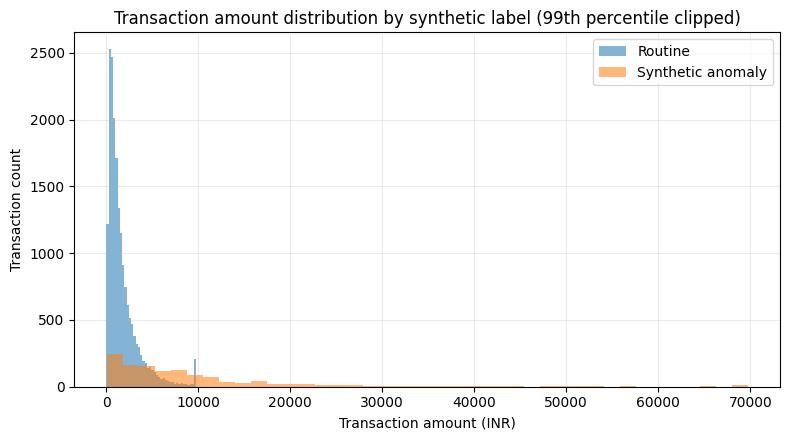

In [8]:
label_summary = (
    df.groupby("known_anomaly")
      .agg(
          transactions=("transaction_id", "count"),
          median_amount=("amount_inr", "median"),
          mean_amount=("amount_inr", "mean"),
          p95_amount=("amount_inr", lambda x: x.quantile(0.95))
      )
      .rename(index={0: "Routine", 1: "Synthetic anomaly"})
)
display(label_summary.round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
for label, group in df.groupby("known_anomaly"):
    group["amount_inr"].dropna().clip(upper=group["amount_inr"].quantile(0.99)).hist(
        bins=40, alpha=0.55, ax=ax, label=("Routine" if label == 0 else "Synthetic anomaly")
    )
ax.set_title("Transaction amount distribution by synthetic label (99th percentile clipped)")
ax.set_xlabel("Transaction amount (INR)")
ax.set_ylabel("Transaction count")
ax.legend()
plt.tight_layout()
plt.show()

## Task B – Feature Engineering

### 9. Create customer-history features using past transactions only

The requested features are:
- `amount_vs_customer_history`: current amount divided by the customer's average amount in earlier transactions.
- `transaction_frequency_60m`: number of earlier transactions by the same customer in the previous 60 minutes.
- `minutes_since_previous`: elapsed minutes since the customer's immediately previous transaction.

For the first transaction in a customer's history, history-based features are missing and will be imputed within the training pipeline. No current or future transaction is included in the historical aggregates.

In [9]:
df = df.sort_values(["customer_id", "transaction_time"]).reset_index(drop=True)

# Previous-only cumulative amount history (exclude current transaction).
df["customer_previous_amount_sum"] = (
    df.groupby("customer_id")["amount_inr"].transform(
        lambda values: values.shift(1).expanding(min_periods=1).mean()
    )
)

df["amount_vs_customer_history"] = (
    df["amount_inr"] / df["customer_previous_amount_sum"]
)

# Time since previous transaction per customer.
df["previous_transaction_time"] = (
    df.groupby("customer_id")["transaction_time"].shift(1)
)

df["minutes_since_previous"] = (
    (df["transaction_time"] - df["previous_transaction_time"])
    .dt.total_seconds() / 60
)

# Count earlier transactions in the trailing 60-minute window.
frequency_values = np.zeros(len(df), dtype=float)

for _, group in df.groupby("customer_id", sort=False):
    times = group["transaction_time"].astype("int64").to_numpy()
    left = 0
    counts = np.zeros(len(group), dtype=float)

    for position in range(len(group)):
        # Move left edge so only events strictly earlier than current and
        # no older than 60 minutes are included.
        while left < position and times[position] - times[left] > 60 * 60 * 1_000_000_000:
            left += 1
        counts[position] = position - left

    frequency_values[group.index.to_numpy()] = counts

df["transaction_frequency_60m"] = frequency_values

engineered_features = [
    "amount_vs_customer_history",
    "transaction_frequency_60m",
    "minutes_since_previous"
]

display(df[[
    "customer_id", "transaction_time", "amount_inr"
] + engineered_features].head(12))

print("\nEngineered feature missingness:")
display(df[engineered_features].isna().sum().to_frame("missing_count"))

,customer_id,transaction_time,amount_inr,amount_vs_customer_history,transaction_frequency_60m,minutes_since_previous
0,C00001,2026-01-02 21:12:14,1005.57,NaN,0.0,NaN
1,C00001,2026-01-04 13:36:18,14140.70,14.062373,0.0,2424.066667
2,C00001,2026-01-05 07:23:16,1643.70,0.217044,0.0,1066.966667
3,C00001,2026-01-08 08:46:17,4380.98,0.782785,0.0,4403.016667
4,C00001,2026-01-24 20:09:38,1430.44,0.270265,0.0,23723.350000
5,C00001,2026-01-27 17:47:23,1554.92,0.343988,0.0,4177.750000
6,C00001,2026-01-28 21:24:51,1393.40,0.346096,0.0,1657.466667
7,C00001,2026-02-02 05:23:02,786.10,0.215372,0.0,6238.183333
8,C00001,2026-02-03 04:20:19,1197.60,0.363794,0.0,1377.283333
9,C00001,2026-02-05 14:50:46,8274.01,2.704572,0.0,3510.450000



Engineered feature missingness:


,missing_count
amount_vs_customer_history,1300
transaction_frequency_60m,0
minutes_since_previous,1200


### 10. Inspect engineered features and unusual patterns

,count,mean,std,min,25%,50%,75%,max
amount_vs_customer_history,18700.0,1.303,2.342,0.012,0.374,0.714,1.381,52.247
transaction_frequency_60m,20000.0,0.011,0.107,0.000,0.000,0.000,0.000,2.000
minutes_since_previous,18800.0,4863.797,4854.194,0.433,1376.879,3371.442,6820.267,56274.150


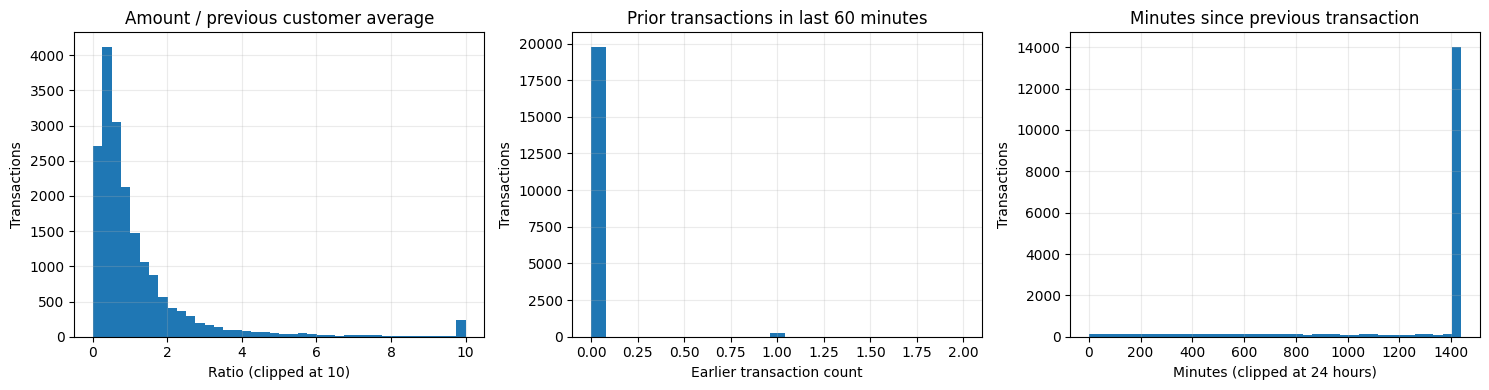

In [10]:
feature_summary = df[engineered_features].describe().T
display(feature_summary.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df["amount_vs_customer_history"].clip(upper=10).dropna().hist(bins=40, ax=axes[0])
axes[0].set_title("Amount / previous customer average")
axes[0].set_xlabel("Ratio (clipped at 10)")
axes[0].set_ylabel("Transactions")

df["transaction_frequency_60m"].hist(bins=25, ax=axes[1])
axes[1].set_title("Prior transactions in last 60 minutes")
axes[1].set_xlabel("Earlier transaction count")
axes[1].set_ylabel("Transactions")

df["minutes_since_previous"].clip(upper=1440).dropna().hist(bins=40, ax=axes[2])
axes[2].set_title("Minutes since previous transaction")
axes[2].set_xlabel("Minutes (clipped at 24 hours)")
axes[2].set_ylabel("Transactions")

plt.tight_layout()
plt.show()

### 11. Prediction-time and privacy audit

The three history features are calculated from prior transactions only. The current transaction amount is known at scoring time, but its customer baseline uses only earlier activity. The target label is never a predictor.

The dataset contains pseudonymous IDs, not direct personal identifiers. Pseudonymization is not full anonymization: access controls and appropriate retention protections are still required.

In [11]:
prediction_audit = pd.DataFrame({
    "feature": [
        "amount_vs_customer_history",
        "transaction_frequency_60m",
        "minutes_since_previous",
        "channel",
        "transaction_hour"
    ],
    "available_at_transaction_time": [True, True, True, True, True],
    "construction": [
        "Current amount divided by average amount of prior customer transactions",
        "Count of prior customer transactions in the trailing 60-minute window",
        "Elapsed time since the immediately previous customer transaction",
        "Channel observed on the current transaction",
        "Hour extracted from current transaction timestamp"
    ]
})
display(prediction_audit)

forbidden_predictors = ["known_anomaly", "transaction_id"]
assert not any(col in engineered_features for col in forbidden_predictors)

,feature,available_at_transaction_time,construction
0,amount_vs_customer_history,True,Current amount divided by average amount of pr...
1,transaction_frequency_60m,True,Count of prior customer transactions in the tr...
2,minutes_since_previous,True,Elapsed time since the immediately previous cu...
3,channel,True,Channel observed on the current transaction
4,transaction_hour,True,Hour extracted from current transaction timestamp


## Task C – Time-based Evaluation

### 12. Prepare chronological train, validation and test sets

The transaction table is sorted by event time:
- First 70%: training
- Next 15%: validation
- Final 15%: test

The validation period is used to choose an alert threshold. The test period is reserved for final evaluation.

In [12]:
model_df = df.sort_values("transaction_time").reset_index(drop=True)

train_end = int(len(model_df) * 0.70)
validation_end = int(len(model_df) * 0.85)

train_df = model_df.iloc[:train_end].copy()
validation_df = model_df.iloc[train_end:validation_end].copy()
test_df = model_df.iloc[validation_end:].copy()

feature_columns = [
    "amount_inr",
    "amount_vs_customer_history",
    "transaction_frequency_60m",
    "minutes_since_previous",
    "transaction_hour"
]
target_column = "known_anomaly"

X_train = train_df[feature_columns]
y_train = train_df[target_column]
X_validation = validation_df[feature_columns]
y_validation = validation_df[target_column]
X_test = test_df[feature_columns]
y_test = test_df[target_column]

split_summary = pd.DataFrame({
    "split": ["Train", "Validation", "Test"],
    "transactions": [len(train_df), len(validation_df), len(test_df)],
    "start_time": [
        train_df["transaction_time"].min(),
        validation_df["transaction_time"].min(),
        test_df["transaction_time"].min()
    ],
    "end_time": [
        train_df["transaction_time"].max(),
        validation_df["transaction_time"].max(),
        test_df["transaction_time"].max()
    ],
    "anomaly_rate_pct": [
        y_train.mean() * 100,
        y_validation.mean() * 100,
        y_test.mean() * 100
    ]
})
display(split_summary.round(3))

,split,transactions,start_time,end_time,anomaly_rate_pct
0,Train,14000,2026-01-01 00:00:04,2026-02-11 16:49:06,6.457
1,Validation,3000,2026-02-11 16:51:19,2026-02-20 18:30:05,6.200
2,Test,3000,2026-02-20 18:31:20,2026-03-01 23:58:00,5.967


### 13. Build a simple baseline and Logistic Regression pipeline

A transparent rule-based baseline flags transactions when the amount is more than four times the customer's previous average. Logistic Regression uses the engineered history features and amount/time fields.

All imputation and scaling are fitted on the training period only.

In [13]:
numeric_features = feature_columns

preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

logistic_model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])
logistic_model.fit(X_train, y_train)

validation_probability = logistic_model.predict_proba(X_validation)[:, 1]
test_probability = logistic_model.predict_proba(X_test)[:, 1]

# Rule-based alert baseline: a deliberately simple, interpretable rule.
baseline_rule_prediction = (
    X_test["amount_vs_customer_history"].fillna(0) >= 4
).astype(int).to_numpy()

majority_prediction = baseline.predict(X_test)

### 14. Compare model performance on the test period

For a rare-event review queue, accuracy is not sufficient. Precision measures how many alerts are labelled unusual; recall measures how many labelled unusual transactions are flagged. PR-AUC summarizes the precision-recall trade-off across thresholds.

In [14]:
def anomaly_metrics(y_true, y_pred, y_score=None):
    result = {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0)
    }
    result["pr_auc"] = (
        average_precision_score(y_true, y_score)
        if y_score is not None else np.nan
    )
    return result

test_prediction_05 = (test_probability >= 0.50).astype(int)

model_comparison = pd.DataFrame([
    {
        "method": "Majority-class baseline",
        **anomaly_metrics(y_test, majority_prediction)
    },
    {
        "method": "Amount ratio rule (>= 4x history)",
        **anomaly_metrics(y_test, baseline_rule_prediction)
    },
    {
        "method": "Logistic Regression (threshold 0.50)",
        **anomaly_metrics(y_test, test_prediction_05, test_probability)
    }
]).set_index("method")

display((model_comparison * 100).round(2))

,accuracy,balanced_accuracy,precision,recall,f1,pr_auc
method,,,,,,
Majority-class baseline,94.03,50.00,0.00,0.00,0.00,NaN
Amount ratio rule (>= 4x history),95.80,70.56,77.32,41.90,54.35,NaN
Logistic Regression (threshold 0.50),89.37,78.91,31.58,67.04,42.93,55.53


### 15. Precision-recall curve

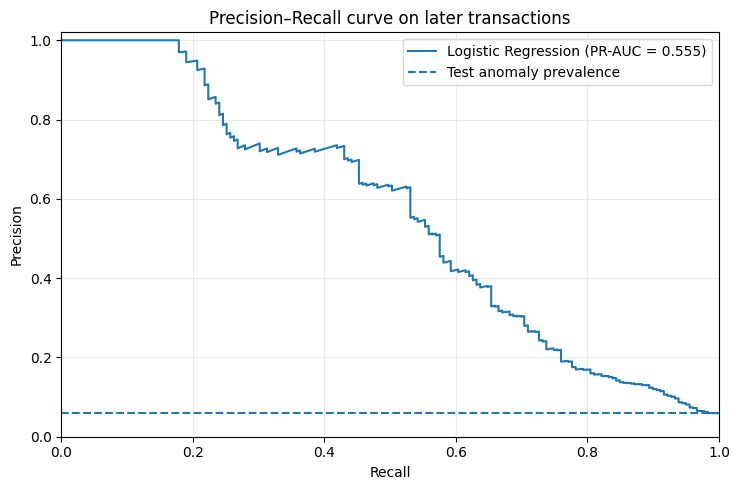

In [15]:
precision_values, recall_values, thresholds = precision_recall_curve(
    y_test, test_probability
)
test_pr_auc = average_precision_score(y_test, test_probability)

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(recall_values, precision_values, label=f"Logistic Regression (PR-AUC = {test_pr_auc:.3f})")
ax.axhline(y_test.mean(), linestyle="--", label="Test anomaly prevalence")
ax.set_title("Precision–Recall curve on later transactions")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend()
plt.tight_layout()
plt.show()

### 16. Select a review threshold on validation data

A review team has limited capacity. For this exercise, choose the threshold that maximizes F1 on the validation period, subject to reviewing no more than 5% of validation transactions. This is a workload constraint, not a claim that all anomalies have equal cost.

The chosen threshold is then evaluated once on the later test period.

In [16]:
threshold_grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
validation_rows = []

for threshold in threshold_grid:
    predicted = (validation_probability >= threshold).astype(int)
    alert_rate = predicted.mean()
    validation_rows.append({
        "threshold": threshold,
        "alerts": int(predicted.sum()),
        "alert_rate": alert_rate,
        "precision": precision_score(y_validation, predicted, zero_division=0),
        "recall": recall_score(y_validation, predicted, zero_division=0),
        "f1": f1_score(y_validation, predicted, zero_division=0)
    })

validation_threshold_results = pd.DataFrame(validation_rows)
eligible_thresholds = validation_threshold_results[
    validation_threshold_results["alert_rate"] <= 0.05
]

if len(eligible_thresholds):
    best_row = eligible_thresholds.loc[eligible_thresholds["f1"].idxmax()]
else:
    best_row = validation_threshold_results.loc[
        validation_threshold_results["alert_rate"].idxmin()
    ]

selected_threshold = float(best_row["threshold"])

print(f"Selected validation threshold: {selected_threshold:.2f}")
display(best_row.to_frame("selected_threshold_result"))

Selected validation threshold: 0.87


,selected_threshold_result
threshold,0.870000
alerts,115.000000
alert_rate,0.038333
precision,0.747826
recall,0.462366
f1,0.571429


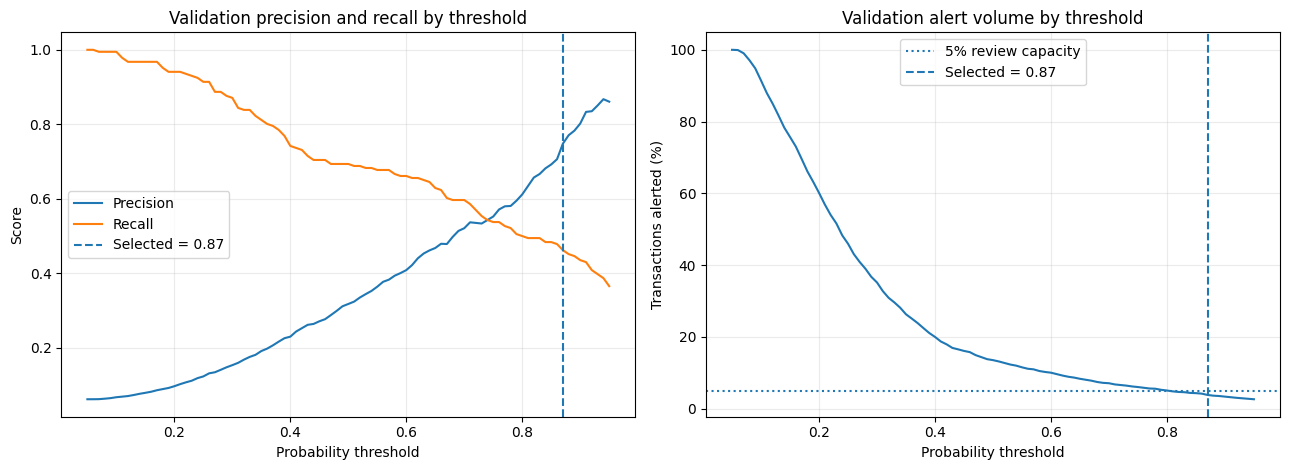

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

axes[0].plot(validation_threshold_results["threshold"], validation_threshold_results["precision"], label="Precision")
axes[0].plot(validation_threshold_results["threshold"], validation_threshold_results["recall"], label="Recall")
axes[0].axvline(selected_threshold, linestyle="--", label=f"Selected = {selected_threshold:.2f}")
axes[0].set_title("Validation precision and recall by threshold")
axes[0].set_xlabel("Probability threshold")
axes[0].set_ylabel("Score")
axes[0].legend()

axes[1].plot(validation_threshold_results["threshold"], validation_threshold_results["alert_rate"] * 100)
axes[1].axhline(5, linestyle=":", label="5% review capacity")
axes[1].axvline(selected_threshold, linestyle="--", label=f"Selected = {selected_threshold:.2f}")
axes[1].set_title("Validation alert volume by threshold")
axes[1].set_xlabel("Probability threshold")
axes[1].set_ylabel("Transactions alerted (%)")
axes[1].legend()

plt.tight_layout()
plt.show()

### 17. Evaluate the selected threshold on the test period

In [18]:
test_prediction_selected = (test_probability >= selected_threshold).astype(int)

test_metrics_selected = anomaly_metrics(
    y_test, test_prediction_selected, test_probability
)

test_tp = int(((test_prediction_selected == 1) & (y_test.to_numpy() == 1)).sum())
test_fp = int(((test_prediction_selected == 1) & (y_test.to_numpy() == 0)).sum())
test_fn = int(((test_prediction_selected == 0) & (y_test.to_numpy() == 1)).sum())
test_alerts = int(test_prediction_selected.sum())

test_summary = pd.DataFrame([{
    "selected_threshold": selected_threshold,
    "test_transactions": len(y_test),
    "alerts_for_review": test_alerts,
    "alert_rate_pct": test_alerts / len(y_test) * 100,
    "true_positive_alerts": test_tp,
    "false_positive_alerts": test_fp,
    "missed_synthetic_anomalies": test_fn,
    "precision": test_metrics_selected["precision"],
    "recall": test_metrics_selected["recall"],
    "f1": test_metrics_selected["f1"],
    "pr_auc": test_metrics_selected["pr_auc"]
}])
display(test_summary.round(3))

,selected_threshold,test_transactions,alerts_for_review,alert_rate_pct,true_positive_alerts,false_positive_alerts,missed_synthetic_anomalies,precision,recall,f1,pr_auc
0,0.87,3000,124,4.133,81,43,98,0.653,0.453,0.535,0.555


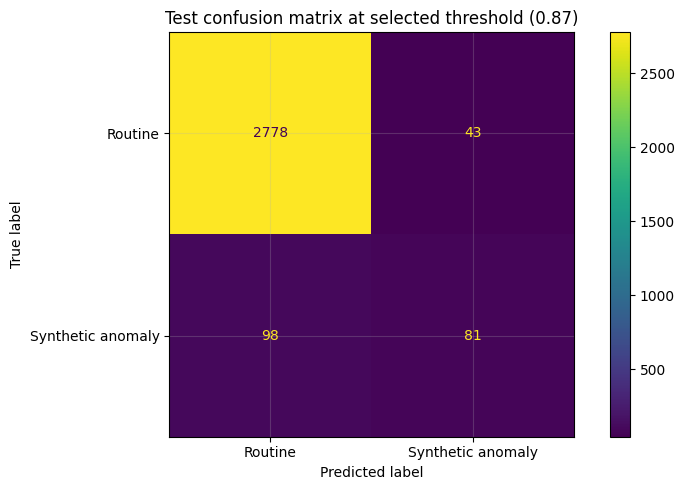

                   precision    recall  f1-score   support

          Routine       0.97      0.98      0.98      2821
Synthetic anomaly       0.65      0.45      0.53       179

         accuracy                           0.95      3000
        macro avg       0.81      0.72      0.75      3000
     weighted avg       0.95      0.95      0.95      3000



In [19]:
cm = confusion_matrix(y_test, test_prediction_selected, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Routine", "Synthetic anomaly"]
)
disp.plot(values_format="d")
plt.title(f"Test confusion matrix at selected threshold ({selected_threshold:.2f})")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    test_prediction_selected,
    target_names=["Routine", "Synthetic anomaly"],
    zero_division=0
))

## Responsible Review and Governance

### 18. False positives and human review

A flagged transaction is an alert, not a fraud verdict. False positives may inconvenience customers, delay legitimate transactions or create unnecessary investigation work. Reviewers should see the reason for the alert, relevant permitted context and an audit trail. No automated punitive action is taken in this notebook.

In [20]:
review_queue = test_df[[
    "transaction_id", "customer_id", "merchant_id",
    "transaction_time", "channel", "amount_inr"
]].copy()

review_queue["anomaly_score"] = test_probability
review_queue["flag_for_review"] = test_prediction_selected
review_queue["known_anomaly_for_evaluation_only"] = y_test.to_numpy()

review_queue = review_queue[
    review_queue["flag_for_review"] == 1
].sort_values("anomaly_score", ascending=False)

print("Sample review queue (synthetic pseudonymous records):")
display(review_queue.head(15))
print("\nReview queue size:", len(review_queue))
print("False positive alerts in test set:", test_fp)

# Important: the evaluation label is included only to audit this synthetic exercise.
# A real analyst review queue must not expose unknown future outcome labels.

Sample review queue (synthetic pseudonymous records):


,transaction_id,customer_id,merchant_id,transaction_time,channel,amount_inr,anomaly_score,flag_for_review,known_anomaly_for_evaluation_only
18749,T0006623,C00716,M0336,2026-02-26 05:08:43,Online,72389.52,1.000000,1,1
19471,T0010391,C00141,M0234,2026-02-28 10:52:40,Card Present,72781.49,1.000000,1,1
19276,T0017713,C00975,M0281,2026-02-27 20:34:34,Online,47714.24,1.000000,1,1
17757,T0016795,C00793,M0233,2026-02-23 02:06:13,ATM,25696.85,1.000000,1,1
18610,T0010779,C00319,M0189,2026-02-25 19:27:43,Mobile Wallet,51471.06,1.000000,1,1
19678,T0001457,C00577,M0214,2026-03-01 01:49:32,Card Present,50765.21,1.000000,1,1
18265,T0009959,C00544,M0284,2026-02-24 20:10:00,Mobile Wallet,53416.60,1.000000,1,1
18844,T0019709,C00710,M0228,2026-02-26 11:51:05,Card Present,23534.41,0.999999,1,1
18040,T0004980,C00310,M0002,2026-02-24 01:49:14,Mobile Wallet,25500.28,0.999999,1,1
18243,T0012508,C00170,M0079,2026-02-24 18:17:16,Online,26324.38,0.999997,1,1



Review queue size: 124
False positive alerts in test set: 43


### 19. Disparate-impact assessment – limitations of available data

This synthetic dataset intentionally does not include protected characteristics such as race, religion, gender or ethnicity. It therefore cannot establish fairness across protected groups. In a real governed evaluation, assess performance across legally and ethically appropriate groups using approved data access, privacy safeguards and expert review. Do not infer sensitive attributes from names, locations or transaction patterns.

In [21]:
# The dataset contains no protected demographic attributes.
sensitive_or_demographic_fields = [
    "race", "religion", "gender", "ethnicity", "health_status"
]
present_sensitive_fields = [
    column for column in df.columns
    if column.lower() in sensitive_or_demographic_fields
]

print("Sensitive demographic fields included:", present_sensitive_fields)
print("Fairness assessment status: NOT EVALUABLE from this synthetic dataset.")

# Operational subgroup checks can still be performed on non-sensitive dimensions,
# but they are not a substitute for a legally reviewed fairness assessment.
channel_error_audit = (
    pd.DataFrame({
        "channel": test_df["channel"].to_numpy(),
        "actual": y_test.to_numpy(),
        "predicted": test_prediction_selected
    })
    .groupby("channel")
    .apply(lambda group: pd.Series({
        "transactions": len(group),
        "alert_rate_pct": group["predicted"].mean() * 100,
        "false_positive_rate_pct": (
            ((group["predicted"] == 1) & (group["actual"] == 0)).sum()
            / max((group["actual"] == 0).sum(), 1) * 100
        ),
        "recall_pct": (
            ((group["predicted"] == 1) & (group["actual"] == 1)).sum()
            / max((group["actual"] == 1).sum(), 1) * 100
        )
    }))
)
display(channel_error_audit.round(2))

Sensitive demographic fields included: []
Fairness assessment status: NOT EVALUABLE from this synthetic dataset.


,transactions,alert_rate_pct,false_positive_rate_pct,recall_pct
channel,,,,
ATM,241.0,2.90,1.32,28.57
Card Present,1160.0,3.79,1.19,45.59
Mobile Wallet,618.0,2.43,0.34,35.14
Online,981.0,5.91,2.71,55.00


## Takeaways

### 20. Evidence-backed findings

The next cell reports findings from this synthetic dataset only. They describe the simulated transaction environment, not real banking activity.

In [22]:
highest_volume_channel = amount_by_channel["transactions"].idxmax()
highest_median_channel = amount_by_channel["median_amount"].idxmax()
highest_hour = hourly_summary["transaction_count"].idxmax()
repeat_merchants = int((merchant_summary["transaction_count"] > 1).sum())
synthetic_anomaly_rate = df["known_anomaly"].mean() * 100

print("SYNTHETIC DATA FINDINGS")
print(f"1. Synthetic anomaly prevalence: {synthetic_anomaly_rate:.2f}%.")
print(f"2. Highest-volume channel: {highest_volume_channel} ({int(amount_by_channel.loc[highest_volume_channel, 'transactions'])} transactions).")
print(f"3. Highest median amount channel: {highest_median_channel} (₹{amount_by_channel.loc[highest_median_channel, 'median_amount']:.2f}).")
print(f"4. Busiest transaction hour: {highest_hour}:00.")
print(f"5. Merchants with repeated transactions: {repeat_merchants} of {len(merchant_summary)}.")
print(f"6. Selected validation alert threshold: {selected_threshold:.2f}.")
print(f"7. Test PR-AUC: {test_metrics_selected['pr_auc']:.3f}.")
print(f"8. Test precision: {test_metrics_selected['precision']:.3f}; recall: {test_metrics_selected['recall']:.3f}.")
print(f"9. Test false-positive alerts: {test_fp} out of {test_alerts} alerts.")

SYNTHETIC DATA FINDINGS
1. Synthetic anomaly prevalence: 6.35%.
2. Highest-volume channel: Card Present (7537 transactions).
3. Highest median amount channel: ATM (₹1663.72).
4. Busiest transaction hour: 4:00.
5. Merchants with repeated transactions: 350 of 350.
6. Selected validation alert threshold: 0.87.
7. Test PR-AUC: 0.555.
8. Test precision: 0.653; recall: 0.453.
9. Test false-positive alerts: 43 out of 124 alerts.


### 21. Recommendations

- Treat model output as a triage signal. Route alerts to trained analysts and preserve a reason code and audit trail.
- Use customer-relative amount features rather than relying only on one global transaction-value threshold.
- Monitor bursts of transactions and unusually short intervals, while considering legitimate customer behaviour.
- Review repeated merchant activity in context; merchant popularity alone is not suspicious.
- Tune the threshold to investigation capacity and the relative cost of false positives and missed anomalies.
- Provide a clear escalation and appeal process for any customer-impacting decision.
- Reassess performance over time as customer behaviour, fraud patterns and transaction channels change.

### 22. Privacy, security and access controls

1. Collect only fields needed for the stated monitoring purpose.
2. Use pseudonymous identifiers in analytical extracts; remember that pseudonymized data may still be re-identifiable.
3. Restrict transaction-level access by role and business need.
4. Encrypt data in transit and at rest, and maintain access logs.
5. Apply retention and deletion schedules approved by the organization.
6. Keep model development, investigation and production permissions separate where practical.
7. Do not expose customer identifiers or investigation outcomes to users who do not need them.
8. Require human review and documented governance before customer-impacting actions.

### 23. Limitations

1. **Synthetic labels:** The target is generated from artificial rules and is not confirmed fraud or real investigator feedback.
2. **Simplified behaviour:** Real spending patterns vary by customer, merchant, geography, season and life events.
3. **Class imbalance:** Accuracy can be misleading when unusual transactions are rare.
4. **History cold start:** New customers may not have enough prior transactions to calculate reliable customer-history features.
5. **Concept drift:** Transaction behaviour and attack patterns can change over time.
6. **Fairness:** The synthetic dataset has no protected-group information, so disparate impact across protected groups cannot be evaluated here.
7. **Human review costs:** Analyst time, customer friction and downstream losses are not fully modelled.
8. **No causal claim:** Correlation between a feature and an anomaly label does not establish a cause.

### 24. Proposed offline evaluation and deployment plan

1. Define a transaction scoring timestamp and ensure every feature is available at that moment.
2. Build customer-history features using strictly prior transactions; test this with chronological unit checks.
3. Use time-based training, validation and test windows. Consider rolling-origin backtests.
4. Compare a simple rules baseline with Logistic Regression and an appropriate anomaly-detection method.
5. Report precision, recall, F1, PR-AUC, false-positive rate, alert volume and review workload.
6. Evaluate at the operating threshold and capacity the investigation team can support.
7. Review false positives and false negatives with trained investigators; record outcomes to improve labels.
8. Conduct privacy, security, fairness and model-risk reviews before deployment.
9. Run in shadow mode before any customer-impacting use.
10. Monitor drift, alert rates, subgroup error patterns, reviewer overrides and customer complaints.

### 25. Final conclusion

This case study demonstrates how transaction EDA, customer-history feature engineering and time-based validation can support anomaly triage. The model flags unusual activity for investigation; it does not determine fraud. False positives, privacy, access controls, fairness and human review are central requirements. All numerical results are illustrative because the dataset and labels are synthetic.